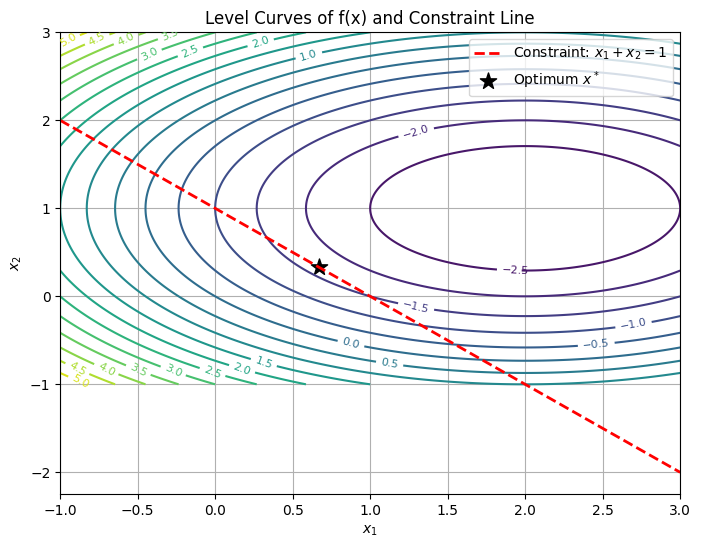

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def f(x1, x2):
    return 0.5 * (x1**2 + 2 * x2**2) - 2 * x1 - 2 * x2

# Create a grid of points
x1 = np.linspace(-1, 3, 400)
x2 = np.linspace(-1, 3, 400)
X1, X2 = np.meshgrid(x1, x2)
Z = f(X1, X2)

# Plot level curves
plt.figure(figsize=(8, 6))
contours = plt.contour(X1, X2, Z, levels=20, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=8)

# Plot the constraint line: x1 + x2 = 1  => x2 = 1 - x1
plt.plot(x1, 1 - x1, 'r--', linewidth=2, label='Constraint: $x_1 + x_2 = 1$')

# Mark the visual optimum
plt.scatter(2/3, 1/3, color='black', marker='*', s=150, label='Optimum $x^*$')

plt.title('Level Curves of f(x) and Constraint Line')
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.legend()
plt.grid(True)
plt.show()

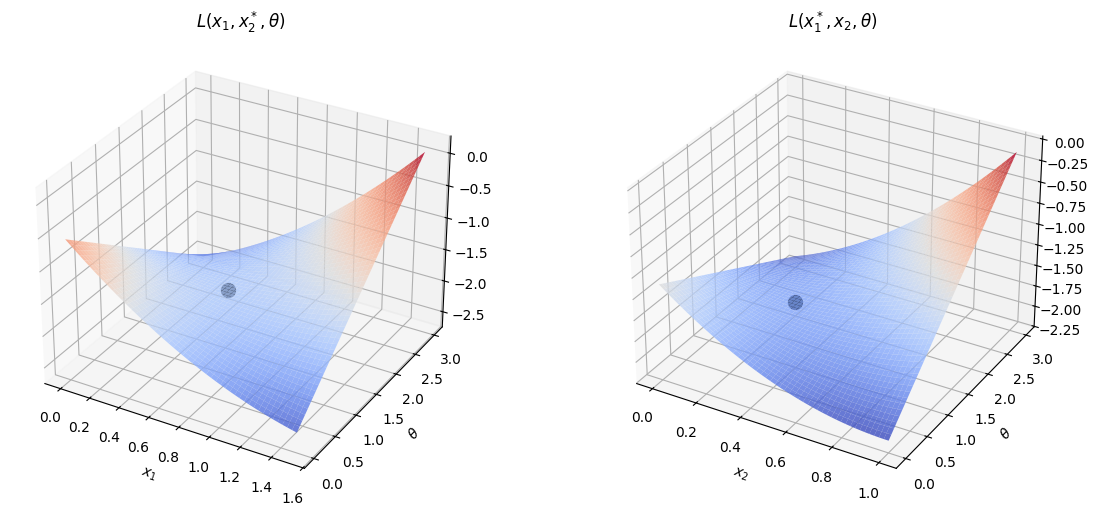

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

# Optimal values
x1_opt, x2_opt, theta_opt = 2/3, 1/3, 4/3

def L_func(x1, x2, theta) -> int:
    f_val = 0.5 * (x1**2 + 2 * x2**2) - 2 * x1 - 2 * x2
    g_val = x1 + x2 - 1
    return f_val + theta * g_val

# Prepare data for L(x1, x2_opt, theta) and L(x1_opt, x2, theta)
theta_vals = np.linspace(0, 3, 50)
x1_vals = np.linspace(0, 1.5, 50)
x2_vals = np.linspace(0, 1, 50)

# Section 1: Varying x1 and theta
X1, T1 = np.meshgrid(x1_vals, theta_vals)
Z1 = L_func(X1, x2_opt, T1)

# Section 2: Varying x2 and theta
X2, T2 = np.meshgrid(x2_vals, theta_vals)
Z2 = L_func(x1_opt, X2, T2)

# Plotting
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_surface(X1, T1, Z1, cmap='coolwarm', alpha=0.8)
ax1.scatter(x1_opt, theta_opt, L_func(x1_opt, x2_opt, theta_opt), color='black', s=100)
ax1.set_title('$L(x_1, x_2^*, \\theta)$')
ax1.set_xlabel('$x_1$'); ax1.set_ylabel('$\\theta$')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot_surface(X2, T2, Z2, cmap='coolwarm', alpha=0.8)
ax2.scatter(x2_opt, theta_opt, L_func(x1_opt, x2_opt, theta_opt), color='black', s=100)
ax2.set_title('$L(x_1^*, x_2, \\theta)$')
ax2.set_xlabel('$x_2$'); ax2.set_ylabel('$\\theta$')

plt.show()